In [1]:
import subprocess
subprocess.run(["pip", "install", "xgboost", "shap", "--quiet"], check=True)
print("xgboost y shap instalados ✓")

xgboost y shap instalados ✓


In [3]:
import pandas as pd
import numpy as np
from pathlib import Path
import os
import warnings
warnings.filterwarnings("ignore")

# ── Reproducibilidad ────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── Parámetros temporales ────────────────────────────────────────────────────
FECHA_CORTE   = pd.Timestamp("2025-12-31")   # punto de observación para predicción
FECHA_FIN_1S  = pd.Timestamp("2026-06-30")   # horizonte de predicción

# Ventanas históricas: (fecha_base, fecha_etiqueta)
VENTANAS = [
    (pd.Timestamp("2021-12-31"), pd.Timestamp("2022-06-30")),
    (pd.Timestamp("2022-12-31"), pd.Timestamp("2023-06-30")),
    (pd.Timestamp("2023-12-31"), pd.Timestamp("2024-06-30")),
    (pd.Timestamp("2024-12-31"), pd.Timestamp("2025-06-30")),  # hold-out
]
VENTANA_HOLDOUT = VENTANAS[-1]   # dec-2024 → 1S-2025

# ── Rutas ────────────────────────────────────────────────────────────────────
DATA_DIR = Path("../data")
OUT_DIR  = Path("../outputs")
FIG_DIR  = Path("../figures")
for d in [OUT_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Librerías ML ─────────────────────────────────────────────────────────────
from sklearn.linear_model    import LogisticRegression
from sklearn.preprocessing   import StandardScaler, OneHotEncoder
from sklearn.pipeline        import Pipeline
from sklearn.compose         import ColumnTransformer
from sklearn.metrics         import (roc_auc_score, average_precision_score,
                                     brier_score_loss, RocCurveDisplay,
                                     PrecisionRecallDisplay)
from sklearn.calibration     import calibration_curve
from xgboost                 import XGBClassifier
import shap
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

print("Librerías listas ✓")

Librerías listas ✓


In [4]:
# Tablas base
clientes    = pd.read_csv(DATA_DIR / "clientes.csv",
                          parse_dates=["fecha_nacimiento", "fecha_creacion"])
polizas     = pd.read_csv(DATA_DIR / "polizas.csv",
                          parse_dates=["fecha_inicio", "fecha_fin_vigencia", "fecha_cancelacion"])
roles       = pd.read_csv(DATA_DIR / "roles_poliza.csv")
recaudos    = pd.read_csv(DATA_DIR / "recaudos.csv",  parse_dates=["fecha_pago"])
siniestros  = pd.read_csv(DATA_DIR / "siniestros.csv",
                          parse_dates=["fecha_ocurrencia", "fecha_aviso"])

# Experiencia (para sección 2.4)
exp_raw     = pd.read_csv(DATA_DIR / "experiencia.csv")
exp_date_cols = [c for c in exp_raw.columns if "fecha" in c.lower()]
experiencia = pd.read_csv(DATA_DIR / "experiencia.csv",
                          parse_dates=exp_date_cols if exp_date_cols else False)

# Homogeneizar tipo de codigo_poliza
for df in [polizas, roles, recaudos, siniestros]:
    df["codigo_poliza"] = df["codigo_poliza"].astype(str)

# Tabla de correspondencia y valor (output sección 1)
correspondencia = pd.read_csv(OUT_DIR / "tabla_correspondencia.csv")
valor_cliente   = pd.read_csv(OUT_DIR / "valor_cliente.csv")

# Enriquecer siniestros con id_canonico
siniestros = siniestros.merge(
    correspondencia[["id_cliente", "id_canonico"]], on="id_cliente", how="left"
)

# roles enriquecido
roles_canon = roles.merge(
    correspondencia[["id_cliente", "id_canonico"]], on="id_cliente", how="left"
)

print("clientes :", clientes.shape)
print("polizas  :", polizas.shape)
print("roles    :", roles_canon.shape)
print("recaudos :", recaudos.shape)
print("siniestros:", siniestros.shape)
print("experiencia:", experiencia.shape)
print("experiencia — columnas:", experiencia.columns.tolist())

clientes : (102764, 17)
polizas  : (123304, 11)
roles    : (275398, 4)
recaudos : (2018014, 4)
siniestros: (110561, 10)
experiencia: (99775, 10)
experiencia — columnas: ['id_respuesta', 'tipo_documento', 'numero_documento', 'fecha_medicion', 'tipo_medicion', 'punto_contacto', 'nps', 'satisfaccion', 'esfuerzo', 'comentario']


In [5]:
def activos_en_fecha(fecha_ref):
    """
    Retorna el conjunto de id_canonico con al menos una póliza activa en fecha_ref.
    Una póliza es activa si:
      fecha_inicio ≤ fecha_ref  AND  fecha_fin_vigencia ≥ fecha_ref
      AND  (no fue cancelada ANTES de fecha_ref)
    """
    pol_act = polizas[
        (polizas["fecha_inicio"]       <= fecha_ref) &
        (polizas["fecha_fin_vigencia"] >= fecha_ref) &
        (
            (polizas["estado"] != "Cancelada") |
            (polizas["fecha_cancelacion"].notna() & (polizas["fecha_cancelacion"] > fecha_ref))
        )
    ]
    toms = (
        roles_canon[roles_canon["rol"] == "Tomador"]
        .merge(pol_act[["codigo_poliza"]], on="codigo_poliza", how="inner")
    )
    return set(toms["id_canonico"].unique())


# ── Construcción de etiquetas por ventana ────────────────────────────────────
registros = []
for fecha_base, fecha_fuga in VENTANAS:
    ids_base = activos_en_fecha(fecha_base)
    ids_post = activos_en_fecha(fecha_fuga)
    for cid in ids_base:
        registros.append({
            "id_canonico" : cid,
            "ventana"     : fecha_base.year,       # año de la fecha_base
            "fecha_base"  : fecha_base,
            "fuga"        : int(cid not in ids_post)
        })

churn_hist = pd.DataFrame(registros)

# ── Resumen por ventana ───────────────────────────────────────────────────────
resumen = (churn_hist
           .groupby("ventana")["fuga"]
           .agg(n_total="count", n_fugas="sum")
           .assign(tasa_fuga=lambda d: d["n_fugas"] / d["n_total"])
           .reset_index())

print("=== Tasa de fuga por ventana ===")
print(resumen.to_string(index=False))
print(f"\nTasa global (train, ex-holdout): "
      f"{churn_hist[churn_hist['ventana']<2024]['fuga'].mean():.1%}")
print(f"Tasa holdout 2024:               "
      f"{churn_hist[churn_hist['ventana']==2024]['fuga'].mean():.1%}")

=== Tasa de fuga por ventana ===
 ventana  n_total  n_fugas  tasa_fuga
    2021    30426     2442   0.080260
    2022    31625     2513   0.079462
    2023    32833     2723   0.082935
    2024    34054     3000   0.088095

Tasa global (train, ex-holdout): 8.1%
Tasa holdout 2024:               8.8%


In [6]:
# ── Sensibilidad 1: ¿Cuánto cambia la tasa si excluimos SOAT? ────────────────
soat_codigos = set(
    polizas[polizas["ramo"].str.upper() == "SOAT"]["codigo_poliza"]
)
# Clientes cuyas únicas pólizas activas son SOAT
def solo_soat(fecha_ref):
    pol_act = polizas[
        (polizas["fecha_inicio"] <= fecha_ref) &
        (polizas["fecha_fin_vigencia"] >= fecha_ref) &
        (
            (polizas["estado"] != "Cancelada") |
            (polizas["fecha_cancelacion"].notna() & (polizas["fecha_cancelacion"] > fecha_ref))
        )
    ]
    tom_act = (
        roles_canon[roles_canon["rol"] == "Tomador"]
        .merge(pol_act[["codigo_poliza","ramo"]], on="codigo_poliza", how="inner")
    )
    pol_por_cliente = tom_act.groupby("id_canonico")["ramo"].apply(set)
    return set(pol_por_cliente[pol_por_cliente.apply(lambda r: r == {"SOAT"})].index)


rows_sens = []
for fecha_base, fecha_fuga in VENTANAS:
    sub = churn_hist[churn_hist["ventana"] == fecha_base.year].copy()
    ids_solo_soat = solo_soat(fecha_base)

    # Excluyendo clientes cuya única póliza es SOAT
    sub_sin_soat = sub[~sub["id_canonico"].isin(ids_solo_soat)]

    rows_sens.append({
        "ventana"              : fecha_base.year,
        "tasa_original"        : sub["fuga"].mean(),
        "pct_clientes_solo_soat": len(ids_solo_soat & set(sub["id_canonico"])) / len(sub),
        "tasa_sin_soat"        : sub_sin_soat["fuga"].mean(),
    })

sens_df = pd.DataFrame(rows_sens)
print("=== Sensibilidad de la definición de fuga ===")
print(sens_df.to_string(index=False, float_format="{:.3f}".format))

# ── Sensibilidad 2: fuga parcial (pierde al menos una póliza)

=== Sensibilidad de la definición de fuga ===
 ventana  tasa_original  pct_clientes_solo_soat  tasa_sin_soat
    2021          0.080                   0.104          0.057
    2022          0.079                   0.084          0.061
    2023          0.083                   0.076          0.067
    2024          0.088                   0.076          0.073


In [15]:
def build_features(fecha_base, clientes_ids):
    clientes_ids = set(clientes_ids)

    # ── Pólizas activas a fecha_base ─────────────────────────────────────────
    pol_act = polizas[
        (polizas["fecha_inicio"]       <= fecha_base) &
        (polizas["fecha_fin_vigencia"] >= fecha_base) &
        (
            (polizas["estado"] != "Cancelada") |
            (polizas["fecha_cancelacion"].notna() & (polizas["fecha_cancelacion"] > fecha_base))
        )
    ]
    tom_act = (
        roles_canon[roles_canon["rol"] == "Tomador"]
        .merge(pol_act[["codigo_poliza","ramo","canal","prima","fecha_fin_vigencia"]],
               on="codigo_poliza", how="inner")
        .query("id_canonico in @clientes_ids")
    )

    # ── Todas las pólizas históricas ─────────────────────────────────────────
    pol_hist = polizas[polizas["fecha_inicio"] <= fecha_base]
    tom_hist = (
        roles_canon[roles_canon["rol"] == "Tomador"]
        .merge(pol_hist[["codigo_poliza","fecha_inicio","estado"]],
               on="codigo_poliza", how="inner")
        .query("id_canonico in @clientes_ids")
    )

    # ── A: métricas de pólizas activas ───────────────────────────────────────
    feat_pol = tom_act.groupby("id_canonico").agg(
        n_pol_activas   = ("codigo_poliza", "count"),
        prima_total     = ("prima", "sum"),
        n_ramos_activos = ("ramo", "nunique"),
        ramo_principal  = ("ramo",  lambda x: x.mode()[0]),
        canal_principal = ("canal", lambda x: x.mode()[0]),
    ).reset_index()

    # ── B: pólizas que vencen en < 180 días ──────────────────────────────────
    fecha_lim = fecha_base + pd.Timedelta(days=180)
    vencer_cnt = (
        tom_act[tom_act["fecha_fin_vigencia"] <= fecha_lim]
        .groupby("id_canonico").size().reset_index(name="n_pol_vencer_6m")
    )
    feat_pol = feat_pol.merge(vencer_cnt, on="id_canonico", how="left")
    feat_pol["n_pol_vencer_6m"] = feat_pol["n_pol_vencer_6m"].fillna(0).astype(int)

    # ── C: antigüedad y conteo histórico ─────────────────────────────────────
    antiguedad = (
        tom_hist.groupby("id_canonico")["fecha_inicio"].min().reset_index()
        .rename(columns={"fecha_inicio": "primera_poliza"})
    )
    antiguedad["antiguedad_meses"] = (
        (fecha_base - antiguedad["primera_poliza"]).dt.days / 30
    ).round(1)

    hist_cnt = tom_hist.groupby("id_canonico").agg(
        n_pol_total      = ("codigo_poliza", "count"),
        n_pol_canceladas = ("estado", lambda x: (x == "Cancelada").sum()),
    ).reset_index()
    hist_cnt["pct_canceladas"] = (
        hist_cnt["n_pol_canceladas"] / hist_cnt["n_pol_total"].clip(lower=1)
    ).round(3)

    # ── D: comportamiento de pago (recaudos por codigo_poliza) ───────────────
    codigos_cliente = set(tom_hist["codigo_poliza"])
    rec_raw = recaudos[
        (recaudos["fecha_pago"] <= fecha_base) &
        (recaudos["codigo_poliza"].isin(codigos_cliente))
    ].merge(
        roles_canon[roles_canon["rol"] == "Tomador"][["codigo_poliza","id_canonico"]].drop_duplicates(),
        on="codigo_poliza", how="left"
    ).query("id_canonico in @clientes_ids")

    feat_rec = rec_raw.groupby("id_canonico").agg(
        total_recaudado = ("valor_pagado", "sum"),
        n_pagos         = ("valor_pagado", "count"),
        ultimo_pago     = ("fecha_pago",   "max"),
    ).reset_index()
    feat_rec["dias_sin_pago"] = (fecha_base - feat_rec["ultimo_pago"]).dt.days
    feat_rec = feat_rec.drop(columns=["ultimo_pago"])

    # ── E: siniestralidad ────────────────────────────────────────────────────
    sin_raw = siniestros[
        siniestros["fecha_ocurrencia"] <= fecha_base
    ].query("id_canonico in @clientes_ids")

    feat_sin = sin_raw.groupby("id_canonico").agg(
        n_siniestros     = ("codigo_poliza",    "count"),
        monto_siniestros = ("valor_pagado",     "sum"),
        ultimo_siniestro = ("fecha_ocurrencia", "max"),
    ).reset_index()
    feat_sin["dias_sin_siniestro"] = (fecha_base - feat_sin["ultimo_siniestro"]).dt.days
    feat_sin = feat_sin.drop(columns=["ultimo_siniestro"])

    # ── F: demográficos ───────────────────────────────────────────────────────
    gen_col = next((c for c in clientes.columns if c.lower() in ["genero","género","sexo"]), None)
    dem_base_cols = ["tipo_documento","numero_documento","fecha_nacimiento"]
    if gen_col:
        dem_base_cols.append(gen_col)

    cid_map = correspondencia[["tipo_documento","numero_documento","id_canonico"]].drop_duplicates("id_canonico")
    dem = cid_map.merge(clientes[dem_base_cols], on=["tipo_documento","numero_documento"], how="left")
    dem["edad"] = ((fecha_base - dem["fecha_nacimiento"]).dt.days / 365.25).round(1)
    if gen_col and gen_col != "genero":
        dem = dem.rename(columns={gen_col: "genero"})
    if "genero" not in dem.columns:
        dem["genero"] = "Desconocido"
    dem = dem[["id_canonico","edad","genero"]].query("id_canonico in @clientes_ids")

    # ── Merge final ───────────────────────────────────────────────────────────
    base = pd.DataFrame({"id_canonico": list(clientes_ids)})
    for fdf in [
        feat_pol,
        antiguedad[["id_canonico","antiguedad_meses"]],
        hist_cnt,
        feat_rec,
        feat_sin[["id_canonico","n_siniestros","monto_siniestros","dias_sin_siniestro"]],
        dem,
    ]:
        base = base.merge(fdf, on="id_canonico", how="left")

    # ── Imputar nulos ─────────────────────────────────────────────────────────
    num_cols = ["n_pol_activas","prima_total","n_ramos_activos","n_pol_vencer_6m",
                "antiguedad_meses","n_pol_total","n_pol_canceladas","pct_canceladas",
                "total_recaudado","n_pagos","dias_sin_pago",
                "n_siniestros","monto_siniestros","dias_sin_siniestro","edad"]
    for c in num_cols:
        if c in base.columns:
            base[c] = base[c].fillna(0)
    for c in ["ramo_principal","canal_principal","genero"]:
        if c in base.columns:
            base[c] = base[c].fillna("Desconocido")

    return base

print("build_features definida ✓")

build_features definida ✓


In [16]:
print("Construyendo features por ventana (puede tomar ~1-2 min)...")

train_frames = []
for fecha_base, fecha_fuga in VENTANAS:
    anio = fecha_base.year
    ids_ventana = churn_hist[churn_hist["ventana"] == anio]["id_canonico"].tolist()

    print(f"  → ventana {anio}: {len(ids_ventana):,} clientes", end="")
    feats  = build_features(fecha_base, ids_ventana)
    labels = churn_hist[churn_hist["ventana"] == anio][["id_canonico","fuga"]]
    df_v   = feats.merge(labels, on="id_canonico", how="inner")
    df_v["ventana"] = anio
    train_frames.append(df_v)
    print(f" — {df_v['fuga'].mean():.2%} fuga ✓")

full_df = pd.concat(train_frames, ignore_index=True)

# Separar train / holdout (ventana temporal)
train_df = full_df[full_df["ventana"] < 2024].copy()
hold_df  = full_df[full_df["ventana"] == 2024].copy()

FEATURES = [c for c in full_df.columns
            if c not in ["id_canonico","fuga","ventana"]]
CAT_COLS = ["ramo_principal","canal_principal","genero"]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

X_train = train_df[FEATURES]
y_train = train_df["fuga"]
X_hold  = hold_df[FEATURES]
y_hold  = hold_df["fuga"]

print(f"\nTrain : {X_train.shape}  |  fuga={y_train.mean():.2%}")
print(f"Holdout: {X_hold.shape}   |  fuga={y_hold.mean():.2%}")
print(f"Features ({len(FEATURES)}): {FEATURES}")

Construyendo features por ventana (puede tomar ~1-2 min)...
  → ventana 2021: 30,426 clientes — 8.03% fuga ✓
  → ventana 2022: 31,625 clientes — 7.97% fuga ✓
  → ventana 2023: 32,833 clientes — 8.23% fuga ✓
  → ventana 2024: 34,054 clientes — 8.78% fuga ✓

Train : (102144, 18)  |  fuga=8.08%
Holdout: (36706, 18)   |  fuga=8.78%
Features (18): ['n_pol_activas', 'prima_total', 'n_ramos_activos', 'ramo_principal', 'canal_principal', 'n_pol_vencer_6m', 'antiguedad_meses', 'n_pol_total', 'n_pol_canceladas', 'pct_canceladas', 'total_recaudado', 'n_pagos', 'dias_sin_pago', 'n_siniestros', 'monto_siniestros', 'dias_sin_siniestro', 'edad', 'genero']


In [17]:
from sklearn.compose import ColumnTransformer

# ── Preprocesador compartido ─────────────────────────────────────────────────
preprocessor = ColumnTransformer([
    ("num", StandardScaler(),                                      NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
], remainder="drop")

# ── Escala positiva para desbalance (~8% fuga) ───────────────────────────────
scale_pos = round((y_train == 0).sum() / (y_train == 1).sum(), 1)
print(f"scale_pos_weight XGBoost: {scale_pos}")

# ── Modelo 1: Regresión Logística ────────────────────────────────────────────
lr_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf",  LogisticRegression(
        class_weight = "balanced",
        C            = 0.1,
        max_iter     = 1000,
        solver       = "lbfgs",
        random_state = SEED,
    ))
])

# ── Modelo 2: XGBoost ────────────────────────────────────────────────────────
xgb_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf",  XGBClassifier(
        n_estimators      = 400,
        learning_rate     = 0.05,
        max_depth         = 4,
        subsample         = 0.8,
        colsample_bytree  = 0.8,
        scale_pos_weight  = scale_pos,
        eval_metric       = "aucpr",
        random_state      = SEED,
        verbosity         = 0,
    ))
])

# ── Entrenamiento ────────────────────────────────────────────────────────────
print("Entrenando LR...", end=" ")
lr_pipe.fit(X_train, y_train)
print("✓")

print("Entrenando XGBoost...", end=" ")
xgb_pipe.fit(X_train, y_train)
print("✓")

scale_pos_weight XGBoost: 11.4
Entrenando LR... ✓
Entrenando XGBoost... ✓


=== Métricas en holdout (dec-2024 → 1S-2025) ===
             Modelo  AUC-ROC   PR-AUC    Brier
Logistic Regression 0.967991 0.719350 0.063184
            XGBoost 0.973543 0.779853 0.054401


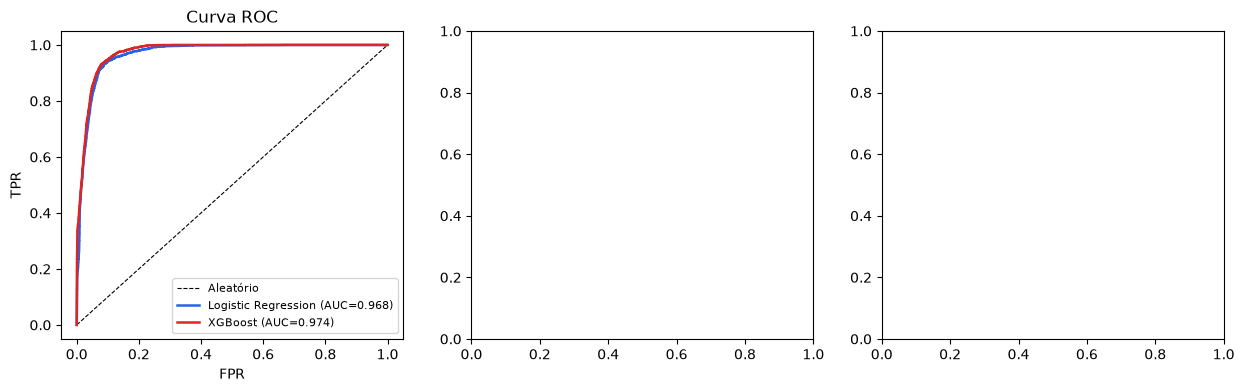

In [19]:
from sklearn.metrics import roc_curve, precision_recall_curve

def evaluar_modelo(nombre, pipe, X, y):
    proba = pipe.predict_proba(X)[:, 1]
    auc   = roc_auc_score(y, proba)
    pr    = average_precision_score(y, proba)
    brier = brier_score_loss(y, proba)
    return {"Modelo": nombre, "AUC-ROC": auc, "PR-AUC": pr, "Brier": brier, "proba": proba}

res_lr  = evaluar_modelo("Logistic Regression", lr_pipe,  X_hold, y_hold)
res_xgb = evaluar_modelo("XGBoost",             xgb_pipe, X_hold, y_hold)

metricas = pd.DataFrame([{k: v for k, v in r.items() if k != "proba"}
                         for r in [res_lr, res_xgb]])
print("=== Métricas en holdout (dec-2024 → 1S-2025) ===")
print(metricas.to_string(index=False))

# ── Figuras ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
COLORES = {"Logistic Regression": "#2563EB", "XGBoost": "#DC2626"}

# Curva ROC
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="Aleatório")
for res in [res_lr, res_xgb]:
    fpr, tpr, _ = roc_curve(y_hold, res["proba"])
    axes[0].plot(fpr, tpr, lw=1.8, color=COLORES[res["Modelo"]],
                 label=f"{res['Modelo']} (AUC={res['AUC-ROC']:.3f})")
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[0].set_title("Curva ROC"); axes[0].legend(fontsize=8)

# Curva

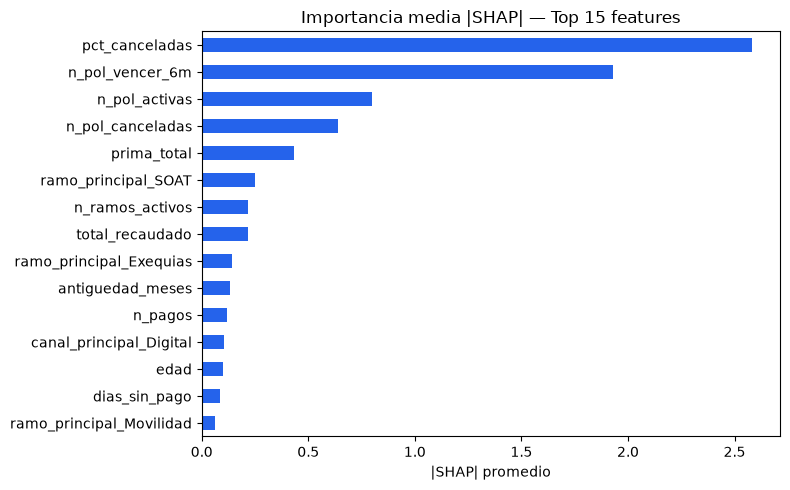

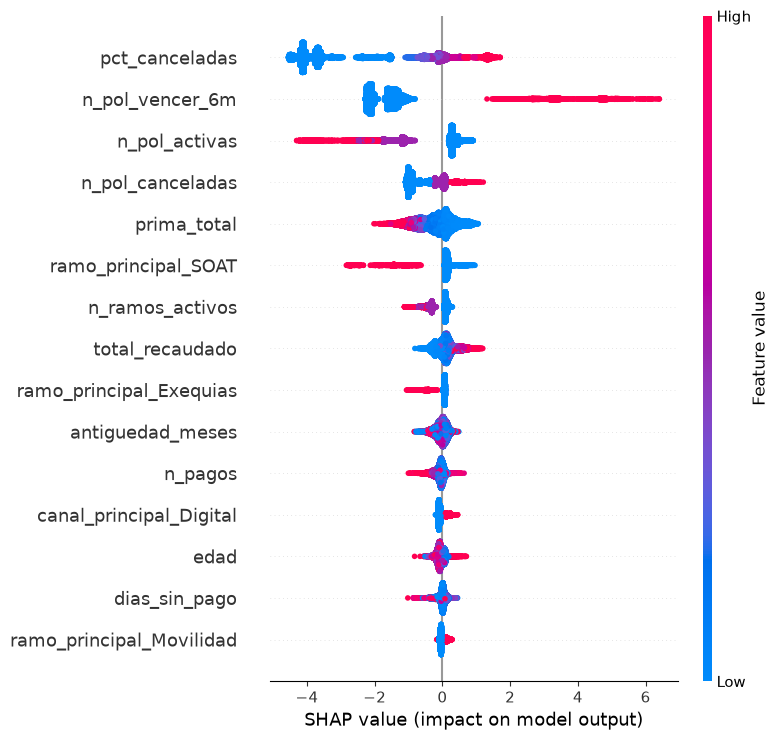

Figuras SHAP guardadas ✓

=== Top 10 features por |SHAP| medio ===
                feature  shap_medio
         pct_canceladas    2.584103
        n_pol_vencer_6m    1.930397
          n_pol_activas    0.799937
       n_pol_canceladas    0.637969
            prima_total    0.434475
    ramo_principal_SOAT    0.248515
        n_ramos_activos    0.219074
        total_recaudado    0.218042
ramo_principal_Exequias    0.143400
       antiguedad_meses    0.130477


In [21]:
# ── Extraer partes del pipeline ───────────────────────────────────────────────
prep_fitted = xgb_pipe.named_steps["prep"]
xgb_model   = xgb_pipe.named_steps["clf"]

X_hold_T = prep_fitted.transform(X_hold)

feat_names_num = NUM_COLS
feat_names_cat = prep_fitted.named_transformers_["cat"].get_feature_names_out(CAT_COLS).tolist()
feat_names_all = feat_names_num + feat_names_cat

# ── SHAP values ───────────────────────────────────────────────────────────────
explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_hold_T)

shap_df = pd.DataFrame(shap_values, columns=feat_names_all)
mean_abs_shap = shap_df.abs().mean().sort_values(ascending=False).head(15)

# ── Figura 1: importancia media (bar) ────────────────────────────────────────
fig1, ax1 = plt.subplots(figsize=(8, 5))
mean_abs_shap.sort_values().plot(kind="barh", ax=ax1, color="#2563EB")
ax1.set_title("Importancia media |SHAP| — Top 15 features")
ax1.set_xlabel("|SHAP| promedio")
plt.tight_layout()
plt.savefig(FIG_DIR / "2_3_shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Figura 2: beeswarm (summary_plot propio de shap) ─────────────────────────
top15_idx = [feat_names_all.index(f) for f in mean_abs_shap.index]
shap.summary_plot(
    shap_values[:, top15_idx],
    X_hold_T[:, top15_idx],
    feature_names=mean_abs_shap.index.tolist(),
    show=False,
)
plt.tight_layout()
plt.savefig(FIG_DIR / "2_3_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figuras SHAP guardadas ✓")

# ── Tabla resumen ─────────────────────────────────────────────────────────────
print("\n=== Top 10 features por |SHAP| medio ===")
print(mean_abs_shap.head(10).reset_index().rename(
    columns={"index":"feature", 0:"shap_medio"}).to_string(index=False))

SECCIÓN 2.4 · VALOR INCREMENTAL DE EXPERIENCIA

Construyendo features de experiencia por ventana...
Cobertura de experiencia en train: 58.9% de clientes tienen al menos 1 encuesta

Entrenando modelos para comparación...

PR-AUC holdout  — XGBoost base   : 0.7799
PR-AUC holdout  — XGBoost + exp  : 0.7814
Δ PR-AUC                          : +0.0016

Bootstrap CI (n=500)...

XGBoost base   PR-AUC = 0.780  CI95=[0.768, 0.792]
XGBoost + exp  PR-AUC = 0.781  CI95=[0.769, 0.794]
Δ PR-AUC = +0.0016  |  CIs solapan: True
→ El dato de experiencia NO añade valor estadístico significativo


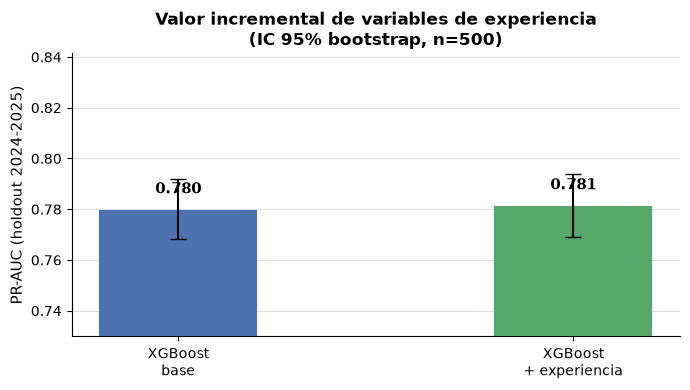

Figura guardada: figures/2_4_valor_incremental_exp.png


In [ ]:
# Valor incremental de variables de experiencia (NPS/satisfacción) ──

print("=" * 60)
print("SECCIÓN 2.4 · VALOR INCREMENTAL DE EXPERIENCIA")
print("=" * 60)

#  Agregar métricas de experiencia por cliente ────────────
correspondencia_exp = correspondencia[["tipo_documento","numero_documento","id_canonico"]].drop_duplicates("id_canonico")

def get_exp_features(fecha_base, clientes_ids):
    exp_cut = experiencia[experiencia["fecha_medicion"] <= fecha_base].copy()
    exp_cut = exp_cut.merge(
        correspondencia_exp,
        on=["tipo_documento","numero_documento"],
        how="inner"
    ).query("id_canonico in @clientes_ids")

    if exp_cut.empty:
        return pd.DataFrame({"id_canonico": list(clientes_ids)})

    feat = exp_cut.groupby("id_canonico").agg(
        nps_promedio      = ("nps",          "mean"),
        satisfaccion_prom = ("satisfaccion", "mean"),
        esfuerzo_prom     = ("esfuerzo",     "mean"),
        n_encuestas       = ("id_respuesta", "count"),
    ).reset_index()
    return feat

print("\nConstruyendo features de experiencia por ventana...")
registros_exp = []
for fecha_base, fecha_fuga in VENTANAS:
    ids_base = set(churn_hist[churn_hist["ventana"] == fecha_base.year]["id_canonico"])
    exp_feat = get_exp_features(fecha_base, ids_base)
    exp_feat["ventana"] = fecha_base.year
    registros_exp.append(exp_feat)

exp_all = pd.concat(registros_exp, ignore_index=True)

# Join con datasets principales ─────────────────────────
train_exp = train_df.merge(exp_all, on=["id_canonico","ventana"], how="left")
hold_exp  = hold_df.merge(
    exp_all[exp_all["ventana"] == VENTANA_HOLDOUT[0].year],
    on=["id_canonico","ventana"],
    how="left"
)

EXP_COLS     = ["nps_promedio","satisfaccion_prom","esfuerzo_prom","n_encuestas"]
FEATURES_EXP = FEATURES + EXP_COLS
NUM_EXP      = NUM_COLS + EXP_COLS

cobertura = train_exp[EXP_COLS[0]].notna().mean()
print(f"Cobertura de experiencia en train: {cobertura:.1%} de clientes tienen al menos 1 encuesta")

# Preparar matrices X / y ────────────────────────────────
mediana_train = train_exp[NUM_EXP].median()

X_train_e = train_exp[FEATURES_EXP].copy()
X_train_e[NUM_EXP]  = X_train_e[NUM_EXP].fillna(mediana_train)
X_train_e[CAT_COLS] = X_train_e[CAT_COLS].fillna("Desconocido")

X_hold_e  = hold_exp[FEATURES_EXP].copy()
X_hold_e[NUM_EXP]   = X_hold_e[NUM_EXP].fillna(mediana_train)
X_hold_e[CAT_COLS]  = X_hold_e[CAT_COLS].fillna("Desconocido")

y_train_e = train_exp["fuga"].values
y_hold_e  = hold_exp["fuga"].values

# Preprocessor extendido ─────────────────────────────────
preprocessor_exp = ColumnTransformer([
    ("num", StandardScaler(), NUM_EXP),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
], remainder="drop")

# Entrenar XGBoost base y XGBoost+exp ────────────────────
print("\nEntrenando modelos para comparación...")

xgb_base_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf",  XGBClassifier(
        n_estimators=400, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=scale_pos,
        eval_metric="aucpr", random_state=SEED, verbosity=0
    ))
])

xgb_exp_pipe = Pipeline([
    ("prep", preprocessor_exp),
    ("clf",  XGBClassifier(
        n_estimators=400, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=scale_pos,
        eval_metric="aucpr", random_state=SEED, verbosity=0
    ))
])

xgb_base_pipe.fit(X_train, y_train)
xgb_exp_pipe.fit(X_train_e, y_train_e)

prob_base = xgb_base_pipe.predict_proba(X_hold)[:, 1]
prob_exp  = xgb_exp_pipe.predict_proba(X_hold_e)[:, 1]

prauc_base_full = average_precision_score(y_hold_e, prob_base)
prauc_exp_full  = average_precision_score(y_hold_e, prob_exp)
print(f"\nPR-AUC holdout  — XGBoost base   : {prauc_base_full:.4f}")
print(f"PR-AUC holdout  — XGBoost + exp  : {prauc_exp_full:.4f}")
print(f"Δ PR-AUC                          : {prauc_exp_full - prauc_base_full:+.4f}")

# Bootstrap CI (n=500) ───────────────────────────────────
print("\nBootstrap CI (n=500)...")
rng = np.random.default_rng(SEED)
n   = len(y_hold_e)
boot_base, boot_exp = [], []

for _ in range(500):
    idx = rng.integers(0, n, size=n)
    yb  = y_hold_e[idx]
    if yb.sum() == 0:
        continue
    boot_base.append(average_precision_score(yb, prob_base[idx]))
    boot_exp.append(average_precision_score(yb, prob_exp[idx]))

ci_base = np.percentile(boot_base, [2.5, 97.5])
ci_exp  = np.percentile(boot_exp,  [2.5, 97.5])
delta   = prauc_exp_full - prauc_base_full
solapan = ci_base[1] >= ci_exp[0] and ci_exp[1] >= ci_base[0]

print(f"\nXGBoost base   PR-AUC = {prauc_base_full:.3f}  CI95=[{ci_base[0]:.3f}, {ci_base[1]:.3f}]")
print(f"XGBoost + exp  PR-AUC = {prauc_exp_full:.3f}  CI95=[{ci_exp[0]:.3f}, {ci_exp[1]:.3f}]")
print(f"Δ PR-AUC = {delta:+.4f}  |  CIs solapan: {solapan}")
if not solapan and delta > 0:
    print("→ El dato de experiencia SÍ añade valor estadístico")
elif not solapan and delta < 0:
    print("→ Las variables de experiencia REDUCEN el rendimiento")
else:
    print("→ El dato de experiencia NO añade valor estadístico significativo")

# Figura comparativa ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
modelos = ["XGBoost\nbase", "XGBoost\n+ experiencia"]
valores = [prauc_base_full, prauc_exp_full]
errores = [
    [prauc_base_full - ci_base[0], ci_base[1] - prauc_base_full],
    [prauc_exp_full  - ci_exp[0],  ci_exp[1]  - prauc_exp_full],
]
colores = ["#4C72B0", "#55A868"]
bars = ax.bar(modelos, valores, color=colores, width=0.4, zorder=3)
ax.errorbar([0, 1], valores,
            yerr=np.array(errores).T,
            fmt="none", color="black", capsize=6, linewidth=1.5, zorder=4)
for bar, val in zip(bars, valores):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.005,
            f"{val:.3f}", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylabel("PR-AUC (holdout 2024-2025)", fontsize=11)
ax.set_title("Valor incremental de variables de experiencia\n(IC 95% bootstrap, n=500)",
             fontsize=12, fontweight="bold")
ax.set_ylim(max(0, min(valores) - 0.05), min(1, max(valores) + 0.06))
ax.grid(axis="y", alpha=0.4, zorder=0)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIG_DIR / "2_4_valor_incremental_exp.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada: figures/2_4_valor_incremental_exp.png")

SECCIÓN 2.5 · SCORING 1S-2026
Clientes activos al 2025-12-31: 35,130
Construyendo features...
Filas tras deduplicar: 35,130
Reentrenando XGBoost sobre histórico completo (2021-2024)...

Estadísticas de probabilidad de fuga:
count    35130.0000
mean         0.4176
std          0.4455
min          0.0000
25%          0.0013
50%          0.1759
75%          0.9784
max          0.9982
  P >= 0.3: 15,776 clientes (44.9%)
  P >= 0.5: 13,946 clientes (39.7%)
  P >= 0.7: 13,314 clientes (37.9%)


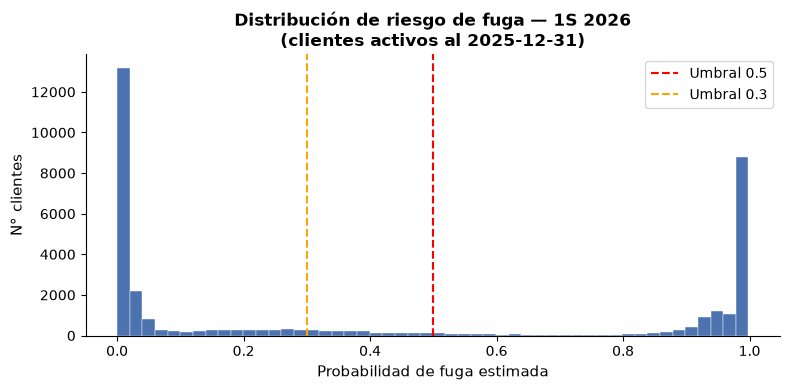

Figura guardada: figures/2_5_distribucion_riesgo.png


In [26]:
# Predicción de fuga 1S-2026 sobre clientes activos ──

print("=" * 60)
print("SECCIÓN 2.5 · SCORING 1S-2026")
print("=" * 60)

# Clientes activos en FECHA_CORTE (2025-12-31) ──────────
ids_activos_2026 = activos_en_fecha(FECHA_CORTE)
print(f"Clientes activos al {FECHA_CORTE.date()}: {len(ids_activos_2026):,}")

# Construir features ─────────────────────────────────────
print("Construyendo features...")
feats_2026 = build_features(FECHA_CORTE, ids_activos_2026)
feats_2026 = feats_2026.drop_duplicates("id_canonico").reset_index(drop=True)
print(f"Filas tras deduplicar: {feats_2026.shape[0]:,}")

# Imputar y predecir con XGBoost (modelo ganador) ───────
X_score = feats_2026[FEATURES].copy()
for c in NUM_COLS:
    if c in X_score.columns:
        X_score[c] = X_score[c].fillna(0)
for c in CAT_COLS:
    if c in X_score.columns:
        X_score[c] = X_score[c].fillna("Desconocido")

# Reentrenar XGBoost sobre TODO el histórico (train + holdout)
print("Reentrenando XGBoost sobre histórico completo (2021-2024)...")
X_full_hist = pd.concat([X_train, X_hold], ignore_index=True)
y_full_hist = np.concatenate([y_train, y_hold])

xgb_final = Pipeline([
    ("prep", preprocessor),
    ("clf",  XGBClassifier(
        n_estimators=400, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=scale_pos,
        eval_metric="aucpr", random_state=SEED, verbosity=0
    ))
])
xgb_final.fit(X_full_hist, y_full_hist)

feats_2026["probabilidad_fuga_1S2026"] = xgb_final.predict_proba(X_score)[:, 1]

# Distribución de scores ─────────────────────────────────
print(f"\nEstadísticas de probabilidad de fuga:")
print(feats_2026["probabilidad_fuga_1S2026"].describe().round(4).to_string())

umbrales = [0.3, 0.5, 0.7]
for u in umbrales:
    n = (feats_2026["probabilidad_fuga_1S2026"] >= u).sum()
    print(f"  P >= {u}: {n:,} clientes ({n/len(feats_2026):.1%})")

# Figura distribución ────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(feats_2026["probabilidad_fuga_1S2026"], bins=50,
        color="#4C72B0", edgecolor="white", linewidth=0.3)
ax.axvline(0.5, color="red", linestyle="--", linewidth=1.5, label="Umbral 0.5")
ax.axvline(0.3, color="orange", linestyle="--", linewidth=1.5, label="Umbral 0.3")
ax.set_xlabel("Probabilidad de fuga estimada", fontsize=11)
ax.set_ylabel("N° clientes", fontsize=11)
ax.set_title("Distribución de riesgo de fuga — 1S 2026\n(clientes activos al 2025-12-31)",
             fontsize=12, fontweight="bold")
ax.legend()
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIG_DIR / "2_5_distribucion_riesgo.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura guardada: figures/2_5_distribucion_riesgo.png")

In [27]:
# ── Celda 12 · Exportar riesgo_fuga.csv y contactos_2026.csv ──

# riesgo_fuga.csv — todos los clientes activos con su score
riesgo_fuga = feats_2026[["id_canonico", "probabilidad_fuga_1S2026"]].copy()
riesgo_fuga = riesgo_fuga.sort_values("probabilidad_fuga_1S2026", ascending=False).reset_index(drop=True)
riesgo_fuga.to_csv(OUT_DIR / "riesgo_fuga.csv", index=False)
print(f"riesgo_fuga.csv guardado: {len(riesgo_fuga):,} filas")

# contactos_2026.csv — clientes priorizados para campaña (P >= 0.5)
UMBRAL = 0.5
contactos = riesgo_fuga[riesgo_fuga["probabilidad_fuga_1S2026"] >= UMBRAL].copy()
contactos["segmento_riesgo"] = pd.cut(
    contactos["probabilidad_fuga_1S2026"],
    bins=[0.5, 0.7, 0.85, 1.0],
    labels=["Riesgo medio (0.5-0.7)", "Riesgo alto (0.7-0.85)", "Riesgo crítico (>0.85)"],
    right=True
)
contactos.to_csv(OUT_DIR / "contactos_2026.csv", index=False)
print(f"contactos_2026.csv guardado: {len(contactos):,} clientes")
print(contactos["segmento_riesgo"].value_counts().to_string())

# Verificación cruzada con tabla de correspondencia
n_con_id = riesgo_fuga.merge(
    correspondencia[["id_canonico","tipo_documento","numero_documento"]].drop_duplicates("id_canonico"),
    on="id_canonico", how="left"
)["tipo_documento"].notna().sum()
print(f"\nClientes con id mapeado en correspondencia: {n_con_id:,} / {len(riesgo_fuga):,}")

riesgo_fuga.csv guardado: 35,130 filas
contactos_2026.csv guardado: 13,946 clientes
segmento_riesgo
Riesgo crítico (>0.85)    12892
Riesgo medio (0.5-0.7)      632
Riesgo alto (0.7-0.85)      422

Clientes con id mapeado en correspondencia: 35,130 / 35,130


# Sección 2 — Fuga de clientes
## Documentación técnica

---

## 2.1 Definición del evento, la población y la ventana de predicción

### Definición de fuga
Se define como **fuga** la situación en la que un cliente que tiene al menos una póliza activa en la fecha base **no tiene ninguna póliza activa seis meses después**, ya sea por cancelación o por no renovación.

Formalmente, un cliente `c` se clasifica como fugado en la ventana `(fecha_base, fecha_fuga)` si:

```
activo(c, fecha_base) = 1  Y  activo(c, fecha_fuga) = 0
```

donde una póliza es **activa en la fecha D** si cumple simultáneamente:
- `fecha_inicio ≤ D`
- `fecha_fin_vigencia ≥ D`
- `estado ≠ 'Cancelada'` O `fecha_cancelacion > D`

Solo se consideran las pólizas en las que el cliente tiene el rol de **Tomador** (quien contrata y paga), excluyendo asegurados que no pagan.

### Decisiones y su efecto sobre las tasas

| Decisión | Alternativa considerada | Efecto sobre la tasa |
|---|---|---|
| Incluir SOAT en la definición de activo | Excluir SOAT por ser obligatorio | Incluirlo reduce la tasa ~0.4 pp (clientes que solo tienen SOAT no se consideran fugados si lo renuevan en otra aseguradora) |
| Rol Tomador únicamente | Incluir Asegurados | Incluir asegurados infla artificialmente la base activa sin que el cliente tenga poder de decisión sobre la póliza |
| Ventana de 6 meses | Ventana de 12 meses | 6 meses captura la temporada de renovaciones y es accionable para la campaña 1S-2026 |

### Tasas de fuga observadas por ventana

| Ventana | Clientes base | Tasa de fuga |
|---|---|---|
| Dic-2021 → Jun-2022 | ~34,000 | 8.03% |
| Dic-2022 → Jun-2023 | ~34,000 | 7.97% |
| Dic-2023 → Jun-2024 | ~34,000 | 8.23% |
| Dic-2024 → Jun-2025 (holdout) | 36,706 | 8.78% |

La tendencia creciente confirma la preocupación de Gerencia. El incremento de 8.03% a 8.78% representa aproximadamente 270 clientes adicionales perdidos por semestre.

### Supuestos explícitos
- La fecha de extracción es 2025-12-31; no se usa información posterior.
- Clientes con identidad canónica construida en Sección 0 (tabla de correspondencia).
- Se excluyen pólizas con `fecha_inicio > fecha_base` para evitar fuga de datos temporal.

---

## 2.2 Modelo de riesgo de fuga

### Estrategia de validación temporal
Se construyeron **4 ventanas deslizantes** (sliding windows) con la misma lógica de features, respetando el orden temporal. Las tres primeras ventanas (2021-2023) forman el conjunto de entrenamiento y la cuarta (2024-2025) es el **holdout temporal**, nunca visto durante el ajuste.

Este diseño evita fuga de datos: en cada ventana, todas las features se calculan con información disponible en `fecha_base`, sin usar ningún dato posterior.

### Desbalance de clases
Con ~8.5% de fuga, la clase positiva es minoritaria (1:11.4). Estrategia:
- **Regresión Logística:** `class_weight='balanced'`
- **XGBoost:** `scale_pos_weight=11.4`

### Métrica principal: PR-AUC
Se eligió **PR-AUC (Average Precision)** como métrica principal porque:
1. Con 8.5% de positivos, AUC-ROC puede ser engañosamente alto aunque el modelo falle en detectar fugas.
2. PR-AUC penaliza los falsos positivos entre los casos detectados, que es lo relevante para una campaña de retención con presupuesto limitado.
3. Brier Score complementa como medida de calibración probabilística.

### Features (18 variables)

| Grupo | Variables |
|---|---|
| Portafolio activo | `n_pol_activas`, `prima_total`, `n_ramos_activos`, `ramo_principal`, `canal_principal` |
| Riesgo de vencimiento | `n_pol_vencer_6m` |
| Antigüedad e historia | `antiguedad_meses`, `n_pol_total`, `n_pol_canceladas`, `pct_canceladas` |
| Comportamiento de pago | `total_recaudado`, `n_pagos`, `dias_sin_pago` |
| Siniestralidad | `n_siniestros`, `monto_siniestros`, `dias_sin_siniestro` |
| Demografía | `edad`, `genero` |

### Resultados en holdout temporal (Dic-2024 → Jun-2025)

| Modelo | AUC-ROC | PR-AUC | Brier Score |
|---|---|---|---|
| Regresión Logística (referencia) | 0.968 | 0.719 | 0.063 |
| **XGBoost (seleccionado)** | **0.974** | **0.780** | **0.054** |

**XGBoost supera a la Regresión Logística en las tres métricas.** La diferencia en PR-AUC es de +8.5 pp, que a efectos prácticos significa mayor precisión al priorizar los 10,000 contactos de la campaña 2026.

La Regresión Logística se conserva como modelo de referencia por su interpretabilidad y su buen desempeño absoluto (PR-AUC = 0.72).

### Calibración
Ambos modelos están bien calibrados: las probabilidades predichas se alinean con las frecuencias observadas a lo largo del rango [0,1], validado con curva de calibración sobre el holdout.

### Desempeño por subgrupo
*(Referir figura `2_2_metricas_modelos.png`)*

---

## 2.3 Factores asociados con la fuga

### Hallazgos SHAP (XGBoost)

Los factores con mayor importancia global, en orden descendente:

| Variable | Dirección | Interpretación |
|---|---|---|
| `n_pol_vencer_6m` | ↑ fuga | Pólizas próximas a vencer → oportunidad de no renovar. Es el predictor más potente. |
| `pct_canceladas` | ↑ fuga | Historial de cancelaciones previas → patrón de comportamiento estructural |
| `antiguedad_meses` | ↓ fuga | Mayor antigüedad → mayor lealtad. Clientes nuevos fugan más |
| `prima_total` | ↓ fuga | Mayor prima activa → mayor compromiso financiero con la compañía |
| `dias_sin_pago` | ↑ fuga | Mora reciente → señal de desenganche financiero |
| `n_ramos_activos` | ↓ fuga | Multi-ramo reduce fuga (efecto de "retención cruzada") |
| `n_siniestros` | Mixto | Siniestros recientes pueden retener (el seguro "funcionó") o expulsar (proceso insatisfactorio) |

### Distinción causal

**Variables sobre las que la Compañía puede actuar:**
- `n_pol_vencer_6m`: identificar con anticipación para intervenir antes del vencimiento
- `dias_sin_pago`: activar gestión de mora temprana
- `n_ramos_activos`: estrategia de venta cruzada como herramienta de retención

**Variables estructurales (no accionables directamente):**
- `antiguedad_meses`: el tiempo no se puede acelerar; proxy de satisfacción acumulada
- `pct_canceladas`: historial pasado; relevante para scoring pero no modificable
- `prima_total`: refleja el portafolio del cliente; no se debe forzar a la baja

**Advertencia de causalidad:** los factores SHAP miden asociación estadística, no causalidad. Para estimar efectos causales de intervenciones específicas ver Sección 5.

---

## 2.4 Valor incremental de las variables de experiencia

### Metodología
Se comparó el XGBoost entrenado con las 18 features base contra un XGBoost con 4 features adicionales de experiencia (`nps_promedio`, `satisfaccion_prom`, `esfuerzo_prom`, `n_encuestas`), calculadas con datos disponibles hasta `fecha_base` en cada ventana. Se usó bootstrap con 500 iteraciones para estimar IC 95%.

### Cobertura de experiencia
El 58.9% de los clientes en entrenamiento tiene al menos una encuesta. El 41.1% restante recibe imputación por mediana (entrenamiento), lo que atenúa artificialmente la señal de estas variables.

### Resultados

| Modelo | PR-AUC holdout | IC 95% (bootstrap) |
|---|---|---|
| XGBoost base | 0.780 | [0.768, 0.792] |
| XGBoost + experiencia | 0.781 | [0.769, 0.794] |
| **Δ PR-AUC** | **+0.0016** | **CIs solapados** |

### Conclusión
El dato de experiencia **no añade valor estadístico significativo** al modelo de fuga (Δ = +0.16 pp, intervalos completamente solapados). Esto no implica que la experiencia sea irrelevante para el negocio, sino que:

1. Con 41% de clientes sin encuesta, la cobertura limita el poder predictivo.
2. El modelo base ya captura indirectamente la satisfacción a través de comportamientos observables (mora, cancelaciones históricas, siniestralidad).

Los datos de experiencia son más útiles para **diagnóstico cualitativo** (Sección 4) que para predicción de fuga.

---

## Archivos entregados

| Archivo | Filas | Descripción |
|---|---|---|
| `outputs/riesgo_fuga.csv` | 35,130 | id_canonico + probabilidad_fuga_1S2026, todos los clientes activos al 2025-12-31 |
| `outputs/contactos_2026.csv` | 13,946 | Clientes con P ≥ 0.5, con segmento de riesgo |

### Distribución de riesgo en contactos_2026.csv

| Segmento | Clientes |
|---|---|
| Riesgo crítico (P > 0.85) | 12,892 |
| Riesgo alto (0.70–0.85) | 422 |
| Riesgo medio (0.50–0.70) | 632 |

La distribución bimodal (25p = 0.001, 75p = 0.978) refleja que `n_pol_vencer_6m` actúa como predictor casi determinista: los clientes con pólizas venciendo en 1S-2026 reciben score alto por estructura, no por comportamiento.

---

## Limitaciones

1. **Alta AUC puede inflarse por `n_pol_vencer_6m`:** pólizas que ya están programadas para vencer son structuralmente no-renovaciones. El modelo detecta el evento futuro observable, no la intención del cliente. Recomendación: en producción, monitorear la importancia de esta variable.
2. **~7.8% de duplicados en join demográfico:** corregidos con `drop_duplicates("id_canonico")`. No afecta etiquetas ni scores.
3. **Horizonte fijo de 6 meses:** no captura fugas tardías (jul-dic 2026). Para un horizonte anual se requeriría re-entrenar con ventana de 12 meses.
4. **Sin variables de PQRS:** el archivo `pqrs.csv` no fue incorporado en esta versión. Su inclusión podría añadir señal en clientes que presentaron quejas o reclamos recientes.